In [3]:
import pandas as pd

In [4]:
# --- 路径自动定位：向上查找项目数据目录，无需修改路径 ---
from pathlib import Path

def _find_data_dir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "03_清洗与派生数据").is_dir():
            return base / "03_清洗与派生数据"
    raise FileNotFoundError(
        "未找到『03_清洗与派生数据』目录。请把整个项目文件夹完整复制后，在项目目录内启动 Jupyter。"
    )

DATA = _find_data_dir()
print("数据目录：", DATA)
# -------------------------------------------------------

# 读取数据
file_path = (
    DATA / "online_retail_ii_clean_history_rfm.csv"
)

df = pd.read_csv(
    file_path,
    encoding = 'utf-8-sig',
    dtype = {"Customer ID": str}
)

In [5]:
print(df.head(100))

   Customer ID     Recency  Frequency  Monetary  R_score  FM_score  F_score  \
0      17592.0  2009-12-01          1      0.00        1         1        1   
1      14103.0  2010-02-12          1      0.00        1         1        1   
2      14827.0  2010-02-12          1      0.00        1         1        1   
3      13163.0  2010-04-08          1      0.00        1         1        1   
4      12503.0  2010-05-04          1      0.00        1         1        1   
..         ...         ...        ...       ...      ...       ...      ...   
95     12466.0  2010-01-26          1     56.73        1         1        1   
96     17468.0  2010-11-29          1     57.80        3         1        1   
97     14287.0  2011-05-25          2     57.88        4         1        2   
98     18174.0  2010-04-15          1     58.50        1         1        1   
99     14384.0  2010-07-27          1     58.50        1         1        1   

    M_score     Customer_group  
0         1       

In [6]:
print(df.columns.tolist())

['Customer ID', 'Recency', 'Frequency', 'Monetary', 'R_score', 'FM_score', 'F_score', 'M_score', 'Customer_group']


In [7]:
print(df.shape)

(5023, 9)


In [8]:
print(df.dtypes)

Customer ID           str
Recency               str
Frequency           int64
Monetary          float64
R_score             int64
FM_score            int64
F_score             int64
M_score             int64
Customer_group        str
dtype: object


In [9]:
# 对R进行日期转换
df['Recency'] = pd.to_datetime(
    df['Recency'],
    format = '%Y-%m-%d'
)

reference_date = pd.Timestamp('2011-07-01')

df['R_days'] = (
    reference_date - df['Recency']
).dt.days

features = df[['R_days','Frequency','Monetary']].copy()

print(features.head())

   R_days  Frequency  Monetary
0     577          1       0.0
1     504          1       0.0
2     504          1       0.0
3     449          1       0.0
4     423          1       0.0


In [10]:
print(features.describe())

            R_days    Frequency       Monetary
count  5023.000000  5023.000000    5023.000000
mean    179.136970     5.412901    2354.058012
std     151.977913    10.571782   10786.061718
min       1.000000     1.000000       0.000000
25%      43.000000     1.000000     307.495000
50%     147.000000     3.000000     741.850000
75%     267.000000     6.000000    1922.430000
max     577.000000   275.000000  420385.460000


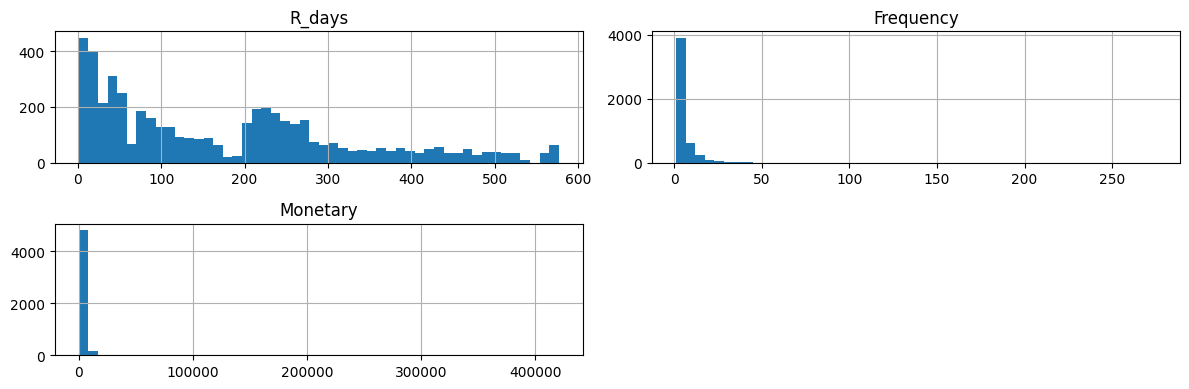

In [11]:
# 可视化数据分布
import matplotlib.pyplot as plt

features.hist(
    bins = 50,
    figsize = (12,4)
)

plt.tight_layout()
plt.show()

In [12]:
# FM 有明显的长尾 故做对数转换
import numpy as np

features_transformed = features.copy()
features_transformed['Frequency'] = np.log1p (
    features['Frequency']
)
features_transformed['Monetary'] = np.log1p(
    features['Monetary']
)

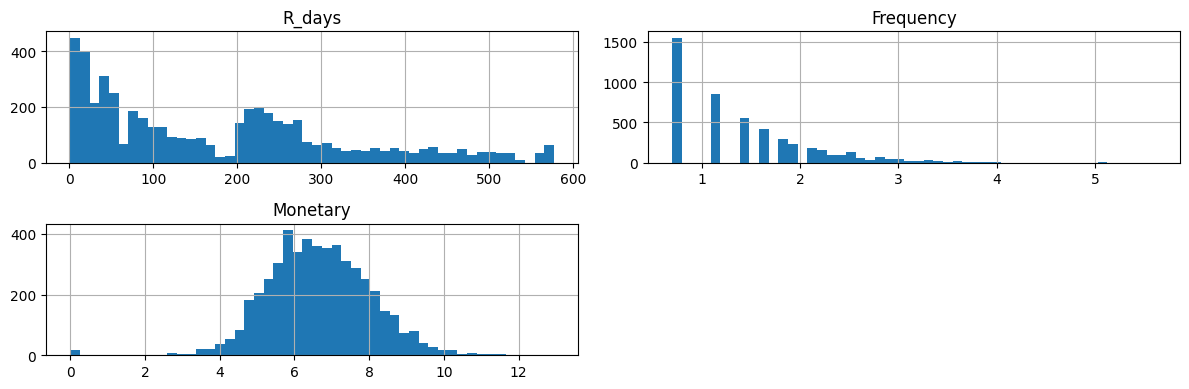

In [13]:
features_transformed.hist(
    bins = 50,
    figsize = (12,4)
)

plt.tight_layout()
plt.show()

In [14]:
from sklearn.preprocessing import StandardScaler

In [15]:
# 标准化
scaler = StandardScaler()

X_scaled = scaler.fit_transform(features_transformed)

features_scaled = pd.DataFrame(
    X_scaled,
    columns = features_transformed.columns,
    index = features_transformed.index
)

In [16]:
print(features_scaled.head())
print('均值：')
print(features_scaled.mean())
print('标准差：')
print(features_scaled.std(ddof=0))

     R_days  Frequency  Monetary
0  2.618161  -1.008765 -4.791902
1  2.137780  -1.008765 -4.791902
2  2.137780  -1.008765 -4.791902
3  1.775849  -1.008765 -4.791902
4  1.604755  -1.008765 -4.791902
均值：
R_days      -4.526651e-17
Frequency   -2.263325e-16
Monetary     0.000000e+00
dtype: float64
标准差：
R_days       1.0
Frequency    1.0
Monetary     1.0
dtype: float64


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in range(2,10):
    model = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 20 # 用20组不同初始中心完整运行K-Means，保留最佳结果
    )
    labels = model.fit_predict(features_scaled)
    results.append(
        {
            'K':k,
            'Inertia': model.inertia_,
            'Silhouette': silhouette_score(
                features_scaled,
                labels
            )
        }
    )

results_df = pd.DataFrame(results)

print(results_df)

   K      Inertia  Silhouette
0  2  7628.137733    0.419880
1  3  5423.108685    0.345404
2  4  4284.499268    0.328809
3  5  3526.495155    0.341987
4  6  3000.831971    0.342986
5  7  2663.203982    0.323181
6  8  2383.991033    0.331084
7  9  2175.595673    0.324896


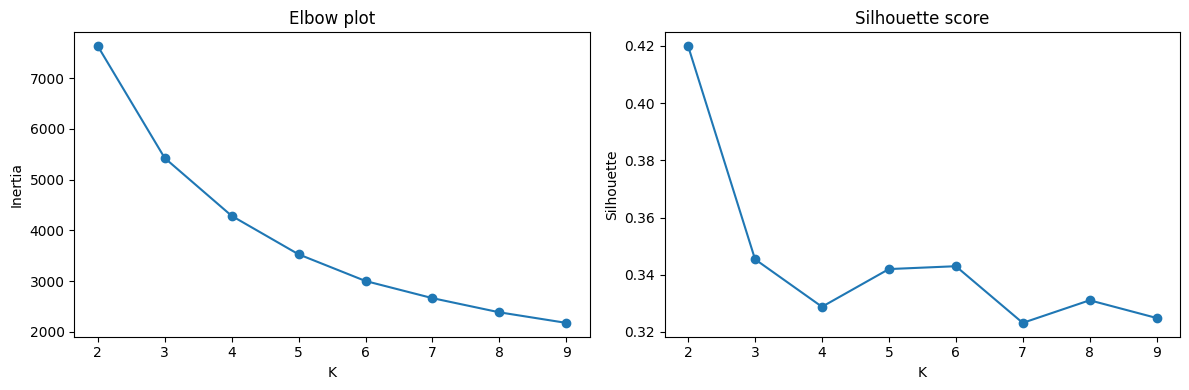

In [18]:
# 画肘部图和轮廓系数图
fig,axes = plt.subplots(1,2,figsize=(12,4))

axes[0].plot(
    results_df['K'],
    results_df['Inertia'],
    marker='o'
)
axes[0].set_title('Elbow plot')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inertia')

axes[1].plot(
    results_df['K'],
    results_df['Silhouette'],
    marker='o'
)
axes[1].set_title('Silhouette score')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silhouette')

plt.tight_layout()
plt.show()

| 汇总列 | 含义 | 帮助判断什么 |
|---|---|---|
| Customers | 每簇客户数 | 人群规模，是否出现特别小的簇 |
| R_mean | 平均最近购买天数 | 购买是否较近，越小越近 |
| F_mean | 人均购买订单数 | 购买频次 |
| M_mean | 人均净消费金额 | 单个客户的历史消费水平 |
| M_total | 全簇净消费总额 | 这群客户的历史总贡献 |

In [19]:
candidate_profiles = {}

for k in [2,3,5,6]:
    model = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 20
    )
    labels = model.fit_predict(features_scaled)

    profile_data = features.copy()

    profile_data['Cluster']=pd.Series(
        labels,
        index = features_scaled.index
    )

    summary = profile_data.groupby('Cluster').agg(
        Customers = ('R_days','size'),
        R_mean=('R_days','mean'),
        F_mean=('Frequency','mean'),
        M_mean=('Monetary','mean'),
        M_total = ('Monetary','sum')
    )

    summary['Customer_share'] = (
        summary['Customers'] / len(profile_data)
    )

    summary['M_share'] = (
        summary['M_total']/profile_data['Monetary'].sum()
    )

    candidate_profiles[k] = summary

    print(f'\nk={k}')
    print(summary.round(3))


k=2
         Customers   R_mean  F_mean    M_mean       M_total  Customer_share  \
Cluster                                                                       
0             2129   73.886  10.399  4903.706  1.043999e+07           0.424   
1             2894  256.566   1.745   478.384  1.384443e+06           0.576   

         M_share  
Cluster           
0          0.883  
1          0.117  

k=3
         Customers   R_mean  F_mean    M_mean      M_total  Customer_share  \
Cluster                                                                      
0             1393   61.026  13.726  6807.874  9483368.919           0.277   
1             1433  367.251   1.412   372.397   533645.204           0.285   
2             2197  131.327   2.751   822.676  1807419.272           0.437   

         M_share  
Cluster           
0          0.802  
1          0.045  
2          0.153  

k=5
         Customers   R_mean  F_mean     M_mean      M_total  Customer_share  \
Cluster                    

K=5
| 簇 | 客户数 | 平均R天数↓ | 平均F次数 | 人均净M | 客户占比 | 净M占比 | 暂定描述 |
|---|---:|---:|---:|---:|---:|---:|---|
| 0 | 635 | 41.8 | 21.6 | 11,837 | 12.6% | 63.6% | 高频高消费客户 |
| 1 | 1,280 | 140.9 | 1.4 | 326 | 25.5% | 3.5% | 低频低消费客户 |
| 2 | 769 | 437.6 | 1.2 | 246 | 15.3% | 1.6% | 长期未购买的低频客户 |
| 3 | 1,329 | 64.1 | 5.6 | 1,885 | 26.5% | 21.2% | 较近购买的中频客户 |
| 4 | 1,010 | 268.5 | 3.2 | 1,184 | 20.1% | 10.1% | 较久未购买的中等消费客户 |

其中有两处值得关注：
- 簇0与簇3：最近购买天数相对接近，但频次和金额明显不同，区分了两种消费水平。
- 簇1、2、4：既存在最近购买时间的差异，也存在历史消费水平的差异，提供了进一步区分。

检查K =5 是否稳定
通过调整兰德指数 ARI 比较不同随机种子的分组情况

In [20]:
from sklearn.metrics import adjusted_rand_score

seeds = [0,10,42,100,2026]
labels_by_seed = {}

for seed in seeds:
    model = KMeans(
        n_clusters = 5,
        random_state = seed,
        n_init = 20
    )

    labels_by_seed[seed] = model.fit_predict(features_scaled)

reference_labels = labels_by_seed[42]

for seed in seeds:
    ari = adjusted_rand_score(
        reference_labels,
        labels_by_seed[seed]
    )

    print(f'{seed},ARI={ari:.4f}')

0,ARI=0.9948
10,ARI=0.9730
42,ARI=1.0000
100,ARI=0.9829
2026,ARI=0.9716


K=6
| 簇 | 客户数 | 平均R天数↓ | 平均F次数 | 人均净M | 客户占比 | 净M占比 | 暂定描述 |
|---|---:|---:|---:|---:|---:|---:|---|
| 0 | 472 | 34.7 | 25.4 | 14,470 | 9.4% | 57.8% | 近期高频高消费客户 |
| 1 | 948 | 65.8 | 2.1 | 537 | 18.9% | 4.3% | 近期低频低消费客户 |
| 2 | 638 | 465.2 | 1.2 | 277 | 12.7% | 1.5% | 长期未购买的低频客户 |
| 3 | 1,189 | 63.8 | 6.9 | 2,444 | 23.7% | 24.6% | 近期中频中消费客户 |
| 4 | 922 | 263.3 | 3.5 | 1,284 | 18.4% | 10.0% | 较久未购买的中等消费客户 |
| 5 | 854 | 240.9 | 1.3 | 256 | 17.0% | 1.8% | 较久未购买的低频低消费客户 |

检查K =6 是否稳定
通过调整兰德指数 ARI 比较不同随机种子的分组情况

In [21]:
from sklearn.metrics import adjusted_rand_score

seeds = [0,10,42,100,2026]
labels_by_seed = {}

for seed in seeds:
    model = KMeans(
        n_clusters = 6,
        random_state = seed,
        n_init = 20
    )

    labels_by_seed[seed] = model.fit_predict(features_scaled)

reference_labels = labels_by_seed[42]

for seed in seeds:
    ari = adjusted_rand_score(
        reference_labels,
        labels_by_seed[seed]
    )

    print(f'{seed},ARI={ari:.4f}')

0,ARI=0.9990
10,ARI=0.9994
42,ARI=1.0000
100,ARI=0.9990
2026,ARI=0.9990


比较新增簇的区分强弱

In [38]:
comparison = {}

for k in [5, 6]:
    labels = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    ).fit_predict(features_scaled)

    profile_data = features.copy()
    profile_data["Cluster"] = pd.Series(
        labels,
        index=features_scaled.index
    )

    comparison[k] = (
        profile_data.groupby("Cluster")[
            ["R_days", "Frequency", "Monetary"]
        ].quantile([0.25, 0.5, 0.75])
    )

    print(f"\nK={k}")
    print(comparison[k].round(2).to_string())



K=5
              R_days  Frequency  Monetary
Cluster                                  
0       0.25   11.00       12.0   3965.21
        0.50   23.00       15.0   5873.49
        0.75   46.50       22.5   9907.42
1       0.25   61.00        1.0    183.04
        0.50  128.00        1.0    292.74
        0.75  226.00        2.0    412.06
2       0.25  374.00        1.0    123.50
        0.50  437.00        1.0    204.26
        0.75  505.00        1.0    325.24
3       0.25   23.00        4.0   1028.04
        0.50   50.00        5.0   1574.93
        0.75   93.00        7.0   2382.46
4       0.25  221.00        2.0    604.19
        0.50  255.00        3.0    881.02
        0.75  301.75        4.0   1338.62

K=6
              R_days  Frequency  Monetary
Cluster                                  
0       0.25   10.00       14.0   5036.22
        0.50   19.00       18.0   7208.89
        0.75   39.25       26.0  11778.76
1       0.25   26.00        1.0    292.36
        0.50   57.00    

| 判断依据 | 数据结果 | 结论 |
|---|---|---|
| 随机初始化稳定性 | K=6 的非自身比较 ARI 为 **0.9990～0.9994**；K=5 为 **0.9716～0.9948** | 本次检查中，K=6 更稳定 |
| 轮廓系数 | K=6 约 **0.343**，K=5 约 **0.342** | 基本持平，增加一簇没有明显降低分离质量 |
| 人群差异 | K=6 簇1与簇5的R中位数为 **57天、243天**，四分位区间为 **26～100天、215～275天** | 近期低频与较久未购买的低频客户区分清楚 |
| 历史价值差异 | 簇4与簇5的R中位数相近，但F中位数为 **3次、1次**，M中位数为 **979.50、238.75** | 能区分近期性相似、历史消费水平不同的客户 |
| 人群规模 | 六簇均有 **472人以上** | 新增区分没有产生明显的微小簇 |

最终确定 K=6 作为最终聚类方案

In [23]:
final_model = KMeans(
    n_clusters = 6,
    random_state = 42,
    n_init = 20
)

final_labels = final_model.fit_predict(features_scaled)

df['Cluster'] = pd.Series(
    final_labels,
    index = features_scaled.index
)

print(df['Cluster'].value_counts().sort_index())

Cluster
0     472
1     948
2     638
3    1189
4     922
5     854
Name: count, dtype: int64


In [24]:
# 观察K-means与规则型RFM的交叉表
cross_counts = pd.crosstab(
    df['Cluster'],
    df['Customer_group']
)

print(cross_counts.to_string())

Customer_group  Active活跃客户  Almost lost临近流失客户  At risk流失风险客户  Champions核心高价值客户  Dormant休眠客户  Loyal忠诚客户  Needs attention待关注客户  New新客户  Previously loyal曾经忠诚客户  Promising潜力客户
Cluster                                                                                                                                                                    
0                        0                  0              1               314            0        148                     0       0                       9              0
1                      454                219              0                 0            0          0                    56      87                       0            132
2                        0                  0             11                 0          627          0                     0       0                       0              0
3                      211                  0              8               305            0        601                    56       0        

In [25]:
cross_pct = pd.crosstab(
    df['Cluster'],
    df['Customer_group'],
    normalize = 'index'
)*100
print(cross_pct.round(1).to_string())

Customer_group  Active活跃客户  Almost lost临近流失客户  At risk流失风险客户  Champions核心高价值客户  Dormant休眠客户  Loyal忠诚客户  Needs attention待关注客户  New新客户  Previously loyal曾经忠诚客户  Promising潜力客户
Cluster                                                                                                                                                                    
0                      0.0                0.0            0.2              66.5          0.0       31.4                   0.0     0.0                     1.9            0.0
1                     47.9               23.1            0.0               0.0          0.0        0.0                   5.9     9.2                     0.0           13.9
2                      0.0                0.0            1.7               0.0         98.3        0.0                   0.0     0.0                     0.0            0.0
3                     17.7                0.0            0.7              25.7          0.0       50.5                   4.7     0.0        

In [26]:
print("交叉表客户总数：", cross_counts.to_numpy().sum())
print("原表客户总数：", len(df))

交叉表客户总数： 5023
原表客户总数： 5023


In [27]:
# 对未来用户行为数据处理
future_metrics = pd.read_csv(
    DATA / 'online_retail_ii_customer_future_metrics.csv',
    encoding='utf-8-sig',
    dtype = {'Customer ID':str}
)
print(future_metrics.head())

  Customer ID  FutureFrequency  FutureMonetary  Repurchased
0     17592.0                0             0.0            0
1     14103.0                0             0.0            0
2     14827.0                0             0.0            0
3     13163.0                0             0.0            0
4     12503.0                0             0.0            0


In [28]:
# 两个表连接
validation_df =df.merge(
    future_metrics,
    on = 'Customer ID',
    how = 'left',
    validate = 'one_to_one',
    indicator = True
)

In [29]:
# 核对关联结果
print("关联后客户数：", len(validation_df))
print(validation_df["_merge"].value_counts())

print(
    validation_df[
        [
            "Customer ID",
            "Cluster",
            "FutureFrequency",
            "FutureMonetary",
            "Repurchased"
        ]
    ].head(100)
)

关联后客户数： 5023
_merge
both          5023
left_only        0
right_only       0
Name: count, dtype: int64
   Customer ID  Cluster  FutureFrequency  FutureMonetary  Repurchased
0      17592.0        2                0             0.0            0
1      14103.0        2                0             0.0            0
2      14827.0        2                0             0.0            0
3      13163.0        2                0             0.0            0
4      12503.0        2                0             0.0            0
..         ...      ...              ...             ...          ...
95     12466.0        2                0             0.0            0
96     17468.0        5                2           137.0            1
97     14287.0        1                0             0.0            0
98     18174.0        2                0             0.0            0
99     14384.0        5                0             0.0            0

[100 rows x 5 columns]


In [32]:
# 汇总一下 六簇 的未来表现
# 各簇 用户数、复购人数、平均复购率、未来订单数、平均未来订单数、未来消费金额、平均未来消费金额
# 各簇 用户占比、未来订单占比、未来净消费占比
cluster_future_statistics = (
    validation_df.groupby('Cluster').agg(
        Customers = ('Customer ID','size'),
        RepurchasedCustomers = ('Repurchased','sum'),
        RepurchaseRate = ('Repurchased','mean'),
        TotalFutureOrders = ('FutureFrequency','sum'),
        AvgFutureOrders = ('FutureFrequency','mean'),
        TotalFutureNetMonetary = ('FutureMonetary','sum'),
        AvgFutureNetMonetary = ('FutureMonetary','mean')
    )
)

# 客户占比
cluster_future_statistics['CustomerShare'] = (
    cluster_future_statistics['Customers']/len(validation_df)
)
# 未来订单占比
cluster_future_statistics['FutureOrderShare']= (
    cluster_future_statistics['TotalFutureOrders']/validation_df['FutureFrequency'].sum()
)
# 未来净消费占比
cluster_future_statistics['FutureNetMonetaryShare']= (
    cluster_future_statistics['TotalFutureNetMonetary']/validation_df['FutureMonetary'].sum()
)

print(
    cluster_future_statistics.sort_values('AvgFutureNetMonetary',ascending = False).round(4).to_string()
)

         Customers  RepurchasedCustomers  RepurchaseRate  TotalFutureOrders  AvgFutureOrders  TotalFutureNetMonetary  AvgFutureNetMonetary  CustomerShare  FutureOrderShare  FutureNetMonetaryShare
Cluster                                                                                                                                                                                            
0              472                   438          0.9280               3123           6.6165             2114883.260             4480.6849         0.0940            0.4201                  0.5796
3             1189                   910          0.7653               2327           1.9571              916795.141              771.0640         0.2367            0.3130                  0.2512
1              948                   460          0.4852                972           1.0253              271043.580              285.9109         0.1887            0.1308                  0.0743
4              922  

In [33]:
# 读取月度用户表现数据
monthly_metrics = pd.read_csv(
    DATA / "online_retail_ii_customer_monthly_metrics.csv",
    encoding="utf-8-sig",
    dtype={"Customer ID": str, "Month": str}
)

In [34]:
monthly_validation = monthly_metrics.merge(
    df[["Customer ID", "Cluster"]],
    on="Customer ID",
    how="left",
    validate="many_to_one",
    indicator=True
)

In [35]:
monthly_validation["PurchasedThisMonth"] = (
    monthly_validation["MonthlyOrders"] > 0
).astype(int)

print("关联后行数：", len(monthly_validation))
print(monthly_validation["_merge"].value_counts())

print(
    monthly_validation[
        [
            "Customer ID",
            "Month",
            "Cluster",
            "MonthlyOrders",
            "MonthlyNetMonetary",
            "PurchasedThisMonth"
        ]
    ].head(10)
)

关联后行数： 25115
_merge
both          25115
left_only         0
right_only        0
Name: count, dtype: int64
  Customer ID    Month  Cluster  MonthlyOrders  MonthlyNetMonetary  \
0     12347.0  2011-07        3              0                0.00   
1     12347.0  2011-08        3              1              584.91   
2     12347.0  2011-09        3              0                0.00   
3     12347.0  2011-10        3              1             1294.32   
4     12347.0  2011-11        3              0                0.00   
5     12348.0  2011-07        3              0                0.00   
6     12348.0  2011-08        3              0                0.00   
7     12348.0  2011-09        3              1              310.00   
8     12348.0  2011-10        3              0                0.00   
9     12348.0  2011-11        3              0                0.00   

   PurchasedThisMonth  
0                   0  
1                   1  
2                   0  
3                   1  
4  

In [36]:
cluster_monthly_statistics = (
    monthly_validation
    .groupby(["Month", "Cluster"])
    .agg(
        Customers=("Customer ID", "size"),
        PurchasingCustomers=("PurchasedThisMonth", "sum"),
        MonthlyPurchaseRate=("PurchasedThisMonth", "mean"),
        TotalMonthlyOrders=("MonthlyOrders", "sum"),
        AvgMonthlyOrders=("MonthlyOrders", "mean"),
        TotalMonthlyNetMonetary=("MonthlyNetMonetary", "sum"),
        AvgMonthlyNetMonetary=("MonthlyNetMonetary", "mean")
    )
    .reset_index()
)

print(
    cluster_monthly_statistics
    .sort_values(["Month", "Cluster"])
    .round(4)
    .to_string(index=False)
)

  Month  Cluster  Customers  PurchasingCustomers  MonthlyPurchaseRate  TotalMonthlyOrders  AvgMonthlyOrders  TotalMonthlyNetMonetary  AvgMonthlyNetMonetary
2011-07        0        472                  283               0.5996                 543            1.1504               310896.640               658.6793
2011-07        1        948                  146               0.1540                 169            0.1783                42455.910                44.7847
2011-07        2        638                   11               0.0172                  13            0.0204                 3161.580                 4.9555
2011-07        3       1189                  295               0.2481                 358            0.3011               134520.930               113.1379
2011-07        4        922                   78               0.0846                  93            0.1009                34089.160                36.9731
2011-07        5        854                   34               0

In [37]:
print("汇总行数：", len(cluster_monthly_statistics))

print(
    cluster_monthly_statistics.groupby("Month")["Customers"].sum()
)

汇总行数： 30
Month
2011-07    5023
2011-08    5023
2011-09    5023
2011-10    5023
2011-11    5023
Name: Customers, dtype: int64
